# 25 — Meshes: Cotangent Laplacians and Spectral Geometric Deep Learning

**Primary reading:** Bronstein, Bruna, Cohen & Veličković, *Geometric Deep Learning*, §4.6, pp. 61–65. We follow its order: geometric meshes → cotangent Laplacian → spectral analysis → spectral filters → GDL blueprint.

**Recall, rather than repeat:** Graph Laplacians and Fourier transforms: `24_graph_laplacian.ipynb`; Laplace–Beltrami on manifolds: `22_fourier_manifolds.ipynb`; local frames and gauge: `23_bundles_gauges.ipynb`; graphs: `11_graph_theory_fundamentals.ipynb`.

**Goals:** Build triangular and quadrilateral torus meshes; derive cotangent weights; analyze eigenmodes, mesh Fourier transforms, and filters; distinguish intrinsic symmetry, locality and transfer across meshes.

## 1. Meshes, triangulations, tessellations

A **tessellation** partitions a domain into tiles with disjoint interiors; these may be polygons or polyhedra. A **mesh** is a discretization with explicit coordinates and incidence/connectivity, often used in numerical analysis or graphics. A **triangulation** is a simplicial decomposition. Thus a triangular surface mesh is a triangulation of a piecewise-linear surface, while a quadrilateral mesh need not be simplicial.

In §4.6 the proto-book focuses on *triangular manifold meshes* $T=(V,E,F)$: vertices, edges and oriented triangular faces. In a closed manifold mesh each edge has two incident faces and each vertex has a disk-like neighborhood. A non-manifold counterexample is three triangles sharing an edge. A graph consisting only of a triangle's boundary does **not** tell us whether the triangular face is filled.

The mesh's **intrinsic metric** can be encoded by edge lengths $\ell_{ij}$ satisfying triangle inequalities. An isometric bending preserves these lengths even if extrinsic vertex coordinates change.

**Example:** A torus has $\chi=V-E+F=0$. 

**Exercise:** Why does adding a diagonal to each quadrilateral change the 1-skeleton but not the underlying torus topology?

## 2. Torus: quad and triangular decompositions

For $R>r>0$ parameterize a torus by
$$
X(u,v)=((R+r\cos v)\cos u,(R+r\cos v)\sin u,r\sin v).
$$
A periodic grid in $(u,v)$ gives quadrilateral cells; split each cell along a diagonal to obtain a triangular mesh. 

**Pseudocode:** generate periodic vertices, enumerate four corners of every grid cell, and add one quad or two triangles.

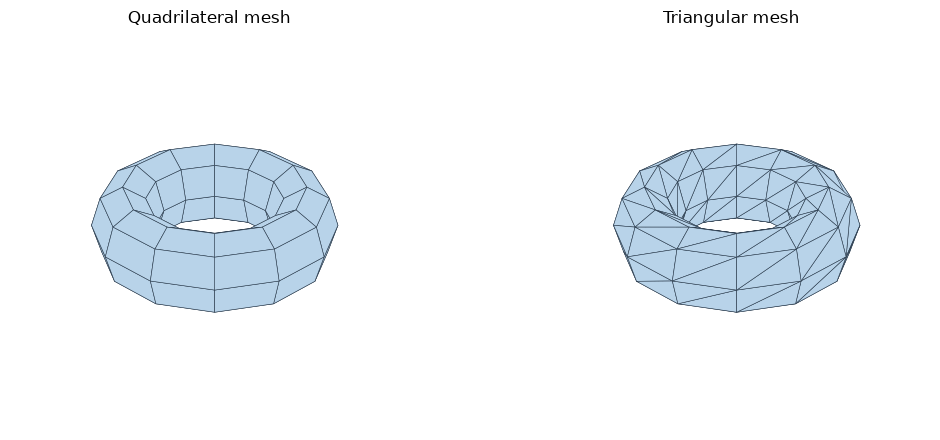

vertices 96 quads 96 triangles 192


In [1]:
# Import numerical and plotting libraries.
import numpy as np
# Import the plotting interface.
import matplotlib.pyplot as plt
# Import sparse linear algebra.
from scipy import sparse
# Import generalized symmetric eigensolver.
from scipy.linalg import eigh
# Import sparse linear solvers.
from scipy.sparse.linalg import spsolve
# Import polygon rendering.
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
# Import incidence counting.
from collections import Counter

# Define a periodic torus mesh generator.
def torus_mesh(nu=12,nv=8,R=2.0,r=0.7):
    # Generate the parameter grid.
    u,v=np.meshgrid(2*np.pi*np.arange(nu)/nu,2*np.pi*np.arange(nv)/nv,indexing='ij')
    # Calculate embedded coordinates.
    V=np.column_stack(((R+r*np.cos(v)).ravel()*np.cos(u).ravel(),(R+r*np.cos(v)).ravel()*np.sin(u).ravel(),(r*np.sin(v)).ravel()))
    # Convert periodic grid coordinates to vertex indices.
    idx=lambda i,j:(i%nu)*nv+j%nv
    # Allocate face lists.
    Q,F=[],[]
    # Iterate over grid cells.
    for i in range(nu):
        # Iterate over the other periodic direction.
        for j in range(nv):
            # Get the four cyclic corners.
            a,b,c,d=idx(i,j),idx(i+1,j),idx(i+1,j+1),idx(i,j+1)
            # Add the quadrilateral.
            Q.append((a,b,c,d))
            # Triangulate it along a diagonal.
            F.extend(((a,b,c),(a,c,d)))
    # Return the vertices and faces.
    return V,np.array(Q),np.array(F)

# Construct the two torus decompositions.
V,Q,F=torus_mesh()
# Create a side-by-side visualization.
fig=plt.figure(figsize=(11,4.5))
# Plot each face decomposition.
for k,(faces,name) in enumerate(((Q,'Quadrilateral mesh'),(F,'Triangular mesh')),1):
    # Add a 3D subplot.
    ax=fig.add_subplot(1,2,k,projection='3d')
    # Draw the polygonal faces.
    ax.add_collection3d(Poly3DCollection(V[faces],facecolor='#b8d3e9',edgecolor='#29394a',linewidth=.4))
    # Set spatial limits.
    ax.set(xlim=(-3,3),ylim=(-3,3),zlim=(-1.1,1.1),title=name)
    # Set geometric aspect.
    ax.set_box_aspect((1,1,.5))
    # Hide axes.
    ax.set_axis_off()
# Arrange the panels.
plt.tight_layout()
# Display the meshes.
plt.show()
# Print mesh sizes.
print('vertices',len(V),'quads',len(Q),'triangles',len(F))

### Check the topology

For a closed triangulated surface each edge is incident to exactly two triangles, hence $3|F|=2|E|$. The torus additionally satisfies $|V|-|E|+|F|=0$. Edge incidence is a useful check, though it does not alone verify the vertex-link manifold condition.

In [2]:
# Count each undirected edge's incident faces.
counts=Counter(tuple(sorted((int(t[a]),int(t[b])))) for t in F for a,b in ((0,1),(1,2),(2,0)))
# Compute Euler characteristic.
chi=len(V)-len(counts)+len(F)
# Verify closed-surface edge incidence.
assert all(x==2 for x in counts.values())
# Verify torus Euler characteristic.
assert chi==0
# Display the result.
print('V,E,F,chi =',len(V),len(counts),len(F),chi)

V,E,F,chi = 96 288 192 0


## 3. Graph Laplacian versus mesh Laplacian

As in `24_graph_laplacian.ipynb`, for vertex signals $f:V\to\mathbb R$,
$$
(Lf)_i=\sum_{j\sim i}w_{ij}(f_i-f_j),\qquad L=D-W.
$$
This is **local permutation-equivariant aggregation**, an instance of the GDL blueprint. A combinatorial Laplacian uses $w_{ij}=1$ on edges and ignores triangle shapes. A geometric graph may use distance-dependent weights, but a triangular mesh has **face angles** and **areas** that allow a principled discretization of Laplace–Beltrami.

**Non-example:** Treating the torus's triangular mesh merely as an unweighted graph discards its intrinsic metric and generally gives a different spectrum.

## 4. Cotangent formula: from finite elements to mesh Laplacian

For an interior edge $\{i,j\}$ shared by triangles $(i,j,k)$ and $(j,i,\ell)$, let $\alpha_{ij},\beta_{ij}$ be the angles **opposite** that edge. Define
$$
c_{ij}=\frac12(\cot\alpha_{ij}+\cot\beta_{ij}).
$$
For a boundary edge there is one cotangent term. The **stiffness matrix** is
$$
S_{ij}=-c_{ij}\ (i\ne j),\qquad S_{ii}=\sum_{j\ne i}c_{ij}.
$$

### Derivation

On a flat triangle $T=(i,j,k)$, let $\phi_i$ be the piecewise-linear nodal hat function with $\phi_i(i)=1$ and $\phi_i(j)=\phi_i(k)=0$. Its gradient is constant and perpendicular to the opposite edge. If $A_T$ denotes triangle area,
$$
\int_T\nabla\phi_i\cdot\nabla\phi_j\,dA
=-\frac{\ell_{ik}\ell_{jk}\cos\angle ikj}{4A_T}
=-\frac12\cot\angle ikj,
$$
using $2A_T=\ell_{ik}\ell_{jk}\sin\angle ikj$. Sum contributions from the two incident triangles to obtain $S_{ij}$.

For the piecewise-linear interpolant $f_h=\sum_i f_i\phi_i$, the **finite-element Dirichlet energy** becomes
$$
\boxed{\mathcal E_h(f)=\frac12\int|\nabla f_h|^2\,dA
=\frac12f^\top Sf
=\frac12\sum_{\{i,j\}\in E}c_{ij}(f_i-f_j)^2.}
$$
Thus $S\succeq0$ even if individual cotangent weights are **negative** (obtuse triangles). In a connected closed mesh, $\ker S$ consists of constants.

**Example:** Two equilateral triangles sharing an edge give $c_{ij}=\cot 60^\circ=1/\sqrt3$. **Non-example:** Cotangent weights are not always a nonnegative graph adjacency matrix.

### Intrinsic nature

The cosine law and triangle area give
$$
\cot\alpha_{ij}=\frac{\ell_{ik}^2+\ell_{jk}^2-\ell_{ij}^2}{4A_{ijk}},
$$
where $A_{ijk}$ is computed from edge lengths using Heron's formula. Therefore cotangent stiffness depends only on the discrete intrinsic metric.

### Crucial mass-matrix distinction

The proto-book's Eq. (25) uses $w_{ij}=c_{ij}/a_i$, with $a_i$ a local vertex area (often one third of incident triangle areas). Set $M=\operatorname{diag}(a_i)$. Then
$$
\Delta_h=M^{-1}S,\qquad S\varphi=\lambda M\varphi.
$$
**$M^{-1}S$ is generally not symmetric in the ordinary Euclidean inner product.** It is self-adjoint in $\langle f,g\rangle_M=f^\top Mg$ and similar to $M^{-1/2}SM^{-1/2}$, which is symmetric PSD. This distinction is essential for the correct mesh Fourier transform.

## 5. Implement cotangent stiffness and barycentric lumped mass

**Pseudocode:** for each triangle, compute its area and the cotangent at each corner; add half that cotangent to the **opposite** edge's weight; distribute one third of the area to each vertex; assemble the symmetric stiffness matrix.

In [3]:
# Define a cotangent stiffness and mass assembler.
def cotan_matrices(V,F):
    # Count mesh vertices.
    n=len(V)
    # Allocate vertex areas.
    area=np.zeros(n)
    # Allocate edge cotangent weights.
    weights={}
    # Visit each triangular face.
    for tri in F:
        # Read vertex indices.
        i,j,k=map(int,tri)
        # Read vertex positions.
        a,b,c=V[[i,j,k]]
        # Calculate twice the triangle area.
        A2=np.linalg.norm(np.cross(b-a,c-a))
        # Reject degenerate triangles.
        if A2<1e-12: raise ValueError('Degenerate face')
        # Accumulate one third of triangle area at each vertex.
        area[[i,j,k]]+=A2/6
        # Compute the cotangents at each vertex.
        ci=np.dot(b-a,c-a)/A2
        # Compute the cotangent at j.
        cj=np.dot(a-b,c-b)/A2
        # Compute the cotangent at k.
        ck=np.dot(a-c,b-c)/A2
        # Associate corner cotangents to opposite edges.
        for p,q,cot in ((j,k,ci),(i,k,cj),(i,j,ck)):
            # Normalize edge orientation.
            edge=tuple(sorted((p,q)))
            # Add the half-cotangent contribution.
            weights[edge]=weights.get(edge,0)+cot/2
    # Allocate sparse matrix entries.
    rows,cols,values=[],[],[]
    # Add the symmetric stiffness block for each edge.
    for (i,j),w in weights.items():
        # Record the row indices.
        rows.extend((i,j,i,j))
        # Record the column indices.
        cols.extend((i,j,j,i))
        # Record diagonal and negative off-diagonal weights.
        values.extend((w,w,-w,-w))
    # Construct the sparse stiffness matrix.
    S=sparse.coo_matrix((values,(rows,cols)),shape=(n,n)).tocsr()
    # Construct the diagonal lumped mass matrix.
    M=sparse.diags(area,format='csr')
    # Return the matrices and weights.
    return S,M,weights

# Assemble the torus cotangent matrices.
S,M,weights=cotan_matrices(V,F)
# Verify symmetry.
assert np.allclose((S-S.T).toarray(),0)
# Verify constants are annihilated.
assert np.allclose(S@np.ones(len(V)),0,atol=1e-10)
# Verify vertex areas are positive.
assert np.all(M.diagonal()>0)
# Report area and negative weights.
print('area',M.diagonal().sum(),'negative edge weights',sum(w<0 for w in weights.values()))

area 52.34375840141967 negative edge weights 45


### Scaling and intrinsic invariance

Uniformly scaling the embedding by $s$ preserves all angles and $S$, while $M$ scales by $s^2$. Hence generalized eigenvalues scale by $s^{-2}$. Rigid motions preserve both matrices. More generally, an isometric bending preserving all edge lengths also preserves the cotangent stiffness and intrinsic areas.

In [4]:
# Assemble matrices after doubling the torus size.
S_big,M_big,_=cotan_matrices(2*V,F)
# Check cotangent stiffness is scale invariant.
assert np.allclose(S_big.toarray(),S.toarray())
# Check that mass scales with area.
assert np.allclose(M_big.diagonal(),4*M.diagonal())
# Report the result.
print('Scaling test passed: S invariant, M scales by four.')

Scaling test passed: S invariant, M scales by four.


## 6. Spectral analysis: eigenmodes and mesh Fourier transform

The natural **generalized eigenproblem** is
$$
S\varphi_k=\lambda_kM\varphi_k,\quad
\Phi^\top M\Phi=I,\quad
0=\lambda_0\le\lambda_1\le\cdots.
$$
The Rayleigh quotient $\lambda=f^\top Sf/(f^\top Mf)$ measures oscillation per unit $L^2$ mass. For a connected closed mesh the first mode is constant.

For a mesh signal $f$,
$$
\boxed{\widehat f=\Phi^\top Mf,\qquad f=\Phi\widehat f.}
$$
Parseval: $f^\top Mf=\sum_k|\widehat f_k|^2$; Dirichlet spectral energy:
$$
f^\top Sf=\sum_k\lambda_k|\widehat f_k|^2.
$$
Compare `24_graph_laplacian.ipynb`, which uses Euclidean-orthonormal graph eigenvectors; the mesh uses **area-weighted** orthonormality. Compare `22_fourier_manifolds.ipynb` for the continuous Laplace–Beltrami interpretation.

**Caveat:** Eigenvectors are sign-ambiguous and repeated eigenspaces have arbitrary orthonormal bases. Even small perturbations can rotate eigenvectors, undermining direct mode-indexed spectral filters across meshes.

First 10 eigenvalues: [0.     0.2631 0.2631 0.8778 0.8778 1.5722 1.5722 2.0888 2.1851 2.1851]


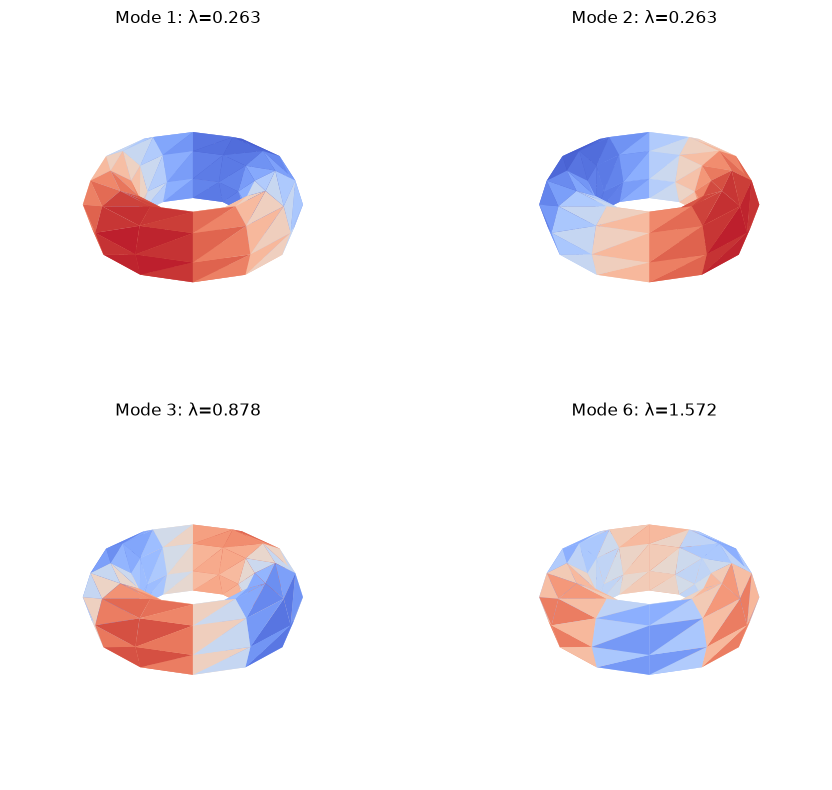

In [5]:
# Solve the symmetric generalized eigenproblem.
lam,Phi=eigh(S.toarray(),M.toarray())
# Verify eigenvalues are nonnegative within numerical tolerance.
assert lam.min()>-1e-8
# Verify mass orthonormality.
assert np.allclose(Phi.T@(M@Phi),np.eye(len(V)),atol=1e-8)
# Verify the eigenproblem.
assert np.allclose(S@Phi,(M@Phi)*lam,atol=1e-8)
# Display the first eigenvalues.
print('First 10 eigenvalues:',np.round(lam[:10],4))
# Create a visualization of four eigenmodes.
fig=plt.figure(figsize=(10,8))
# Select nonconstant modes.
for p,k in enumerate((1,2,3,6),1):
    # Create a 3D axis.
    ax=fig.add_subplot(2,2,p,projection='3d')
    # Read the mode values.
    values=Phi[:,k]
    # Normalize values for color display.
    values=values/(np.max(np.abs(values))+1e-12)
    # Average values over each face.
    fv=values[F].mean(axis=1)
    # Map values to colors.
    colors=plt.get_cmap('coolwarm')((fv+1)/2)
    # Draw colored faces.
    ax.add_collection3d(Poly3DCollection(V[F],facecolors=colors,edgecolor='none'))
    # Set view limits and mode label.
    ax.set(xlim=(-3,3),ylim=(-3,3),zlim=(-1.1,1.1),title=f'Mode {k}: λ={lam[k]:.3f}')
    # Fix aspect.
    ax.set_box_aspect((1,1,.5))
    # Hide axes.
    ax.set_axis_off()
# Arrange plots.
plt.tight_layout()
# Show spectral modes.
plt.show()

## 7. Spectral convolution, filtering and diffusion (§4.6)

For a transfer function $h(\lambda)$, define
$$
h(\Delta_h)f=\Phi\operatorname{diag}(h(\lambda_k))\Phi^\top Mf.
$$
This is the mass-weighted version of the proto-book's spectral convolution formula. Heat filtering uses $h_t(\lambda)=e^{-t\lambda}$, attenuating high-frequency components.

**Why not learn one independent parameter per eigenvector?** A coefficient indexed by mode number is tied to a particular mesh's basis and generally does not transfer across shapes or remeshings. A function $h(\lambda)$ is a more natural shared filter, though discretization and spectral normalization still matter.

**GDL interpretation:** a spectral multiplier is intrinsic, permutation-equivariant and isotropic; it processes the mesh using intrinsic geometry rather than arbitrary vertex order.

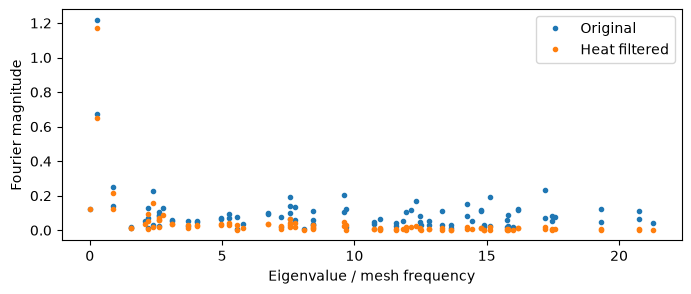

Dirichlet energy: 4.048149359192829 → 0.46229305608444693


In [6]:
# Create a reproducible noisy mesh signal.
rng=np.random.default_rng(7)
# Mix smooth modes and random noise.
f=Phi[:,1]+.7*Phi[:,2]+.15*rng.normal(size=len(V))
# Compute the mass-weighted Fourier transform.
fhat=Phi.T@(M@f)
# Verify inverse Fourier reconstruction.
assert np.allclose(Phi@fhat,f)
# Verify Parseval.
assert np.isclose(f@(M@f),fhat@fhat)
# Select diffusion time.
t=.15
# Apply a heat spectral multiplier.
filtered=Phi@(np.exp(-t*lam)*fhat)
# Compute initial Dirichlet energy.
E0=.5*f@(S@f)
# Compute filtered Dirichlet energy.
E1=.5*filtered@(S@filtered)
# Verify smoothing decreases energy.
assert E1<=E0+1e-8
# Plot spectral coefficient magnitudes.
plt.figure(figsize=(8,3))
# Plot the original spectrum.
plt.plot(lam,np.abs(fhat),'.',label='Original')
# Plot the filtered spectrum.
plt.plot(lam,np.abs(np.exp(-t*lam)*fhat),'.',label='Heat filtered')
# Label the plot.
plt.xlabel('Eigenvalue / mesh frequency')
# Label the vertical axis.
plt.ylabel('Fourier magnitude')
# Add the legend.
plt.legend()
# Display the plot.
plt.show()
# Report energy change.
print('Dirichlet energy:',E0,'→',E1)

## 8. Polynomial spectral filters = local message passing

If $h(\lambda)=\sum_{k=0}^r\alpha_k\lambda^k$, then
$$
h(\Delta_h)f=\sum_{k=0}^r\alpha_k\Delta_h^k f.
$$
Since $\Delta_h=M^{-1}S$ has one-hop sparsity, the degree-$r$ filter accesses at most **$r$-hop neighborhoods**. This realizes the GDL blueprint by repeated local, shared aggregation without computing eigenvectors. See Defferrard et al. (2016) for Chebyshev polynomial filters.

**Resolution limitation:** Two hops on a coarse mesh can cover much more physical surface area than two hops on a fine mesh. Thus fixed-hop locality does not imply resolution independence.

In [7]:
# Define a sparse polynomial filter.
def polynomial_filter(f,coeffs,S,masses):
    # Allocate the filtered output.
    result=np.zeros_like(f,dtype=float)
    # Initialize the zeroth Laplacian power.
    term=f.copy()
    # Visit coefficients in ascending power order.
    for alpha in coeffs:
        # Accumulate the current polynomial term.
        result+=alpha*term
        # Compute the next Laplacian power.
        term=(S@term)/masses
    # Return the filtered signal.
    return result

# Choose a degree-two filter.
coeffs=[1.,-.12,.01]
# Evaluate it through sparse local operations.
spatial=polynomial_filter(f,coeffs,S,M.diagonal())
# Evaluate the same polynomial on the eigenvalues.
response=sum(alpha*lam**k for k,alpha in enumerate(coeffs))
# Reconstruct the spectral result.
spectral=Phi@(response*fhat)
# Verify the two formulations agree.
assert np.allclose(spatial,spectral,atol=1e-8)
# Report numerical error.
print('Polynomial filter discrepancy:',np.max(np.abs(spatial-spectral)))

Polynomial filter discrepancy: 1.887379141862766e-15


## 9. Rational filters and resolution (§4.6)

The proto-book discusses rational filters, including Cayley spectral filters based on $(\lambda-i)/(\lambda+i)$ (Levie et al., 2018), as an alternative to fixed-hop polynomial filters.

A simple resolvent example is
$$
h_\tau(\lambda)=\frac1{1+\tau\lambda},\qquad
(M+\tau S)y=Mf.
$$
This is an implicit diffusion step and is computed by a sparse linear solve. Rational filters are **not automatically** resolution-independent; transfer requires compatible intrinsic scaling and adequate discretization.

In [8]:
# Set a rational-filter diffusion time.
tau=.2
# Solve the sparse linear system.
rational=spsolve(M+tau*S,M@f)
# Compute the equivalent spectral response.
rational_spectral=Phi@((1/(1+tau*lam))*fhat)
# Verify the spatial and spectral formulations agree.
assert np.allclose(rational,rational_spectral,atol=1e-8)
# Print the numerical discrepancy.
print('Rational filter discrepancy:',np.max(np.abs(rational-rational_spectral)))

Rational filter discrepancy: 7.494005416219807e-16


## 10. Main synthesis: spectral meshes and the GDL blueprint

| Blueprint ingredient | Mesh realization |
|---|---|
| Domain | Oriented triangular mesh $(V,E,F)$ with intrinsic lengths and areas |
| Features | Vertex scalar fields or $n\times d$ feature matrices; tangent vectors require additional structure |
| Symmetry | Vertex relabeling equivariance; intrinsic isometry invariance of cotan geometry |
| Locality | Cotangent Laplacian is one-hop; degree-$r$ polynomials are $r$-hop |
| Shared filters | Learned function $h(\lambda)$ rather than one coefficient per mesh eigenvector |
| Aggregation | $(\Delta_hf)_i=a_i^{-1}\sum_jc_{ij}(f_i-f_j)$ |

**Key connection:** Laplacian eigenfunctions supply an intrinsic Fourier basis, while spectral transfer functions supply the filters. Polynomial filters recover sparse message passing. This connects the **spectral** and **spatial** viewpoints within the GDL blueprint.

**Isotropic versus anisotropic:** Scalar Laplacian multipliers do not distinguish tangent directions. A mesh has cyclic ordering of neighbors, but selecting an angular origin requires a local frame. For direction-sensitive filters, consult `23_bundles_gauges.ipynb`: gauge transformations and parallel transport matter. A cotangent Laplacian on scalar vertex signals is **not**, by itself, a gauge-equivariant tangent-vector convolution.

**Transfer caveat:** Intrinsic weights do not guarantee identical finite-resolution spectra across remeshings. Individual eigenvectors can be unstable; spectral functions are preferable to mode-indexed coefficients. Resolution, numerical convergence, and mesh quality remain important.

## 11. Exercises

1. Give a quad mesh that is not a triangulation; triangulate it in two different ways.
2. Verify $3F=2E$ and $V-E+F=0$ on torus meshes of several resolutions.
3. Explain why an edge with three incident faces violates the manifold condition.
4. Derive the triangle hat-function gradient and cotangent stiffness formula.
5. Use Heron's formula to express cotangent weights entirely in terms of edge lengths.
6. Construct an obtuse triangle with a negative cotangent; explain why $S\succeq0$ nevertheless.
7. Prove that the constant signal lies in $\ker S$.
8. Derive the generalized eigenproblem from the finite-element weak formulation.
9. Verify $f^\top Sf=\sum_k\lambda_k|\widehat f_k|^2$ numerically.
10. Compare combinatorial and cotangent Laplacian eigenvalues on the same torus.
11. Compare the first few generalized eigenvalues at resolutions $(8,6),(12,8),(16,12)$.
12. Explain eigenvector sign ambiguity and repeated-eigenspace ambiguity.
13. Prove heat diffusion decreases Dirichlet energy.
14. Construct a high-pass filter $h(\lambda)=1-e^{-t\lambda}$.
15. Show that degree-$r$ polynomial filters are supported within $r$ hops.
16. Compare the physical radius of a two-hop neighborhood on coarse and fine meshes.
17. Derive $(M+\tau S)y=Mf$ for the rational resolvent filter.
18. Explain which part of the GDL blueprint cotangent aggregation realizes.
19. Explain why scalar mesh Laplacians do not automatically define gauge-equivariant vector-field filters.
20. **Research exercise:** triangulate the same torus quad mesh using the opposite diagonal; compare spectra and low-frequency eigenspaces.

## References

- Bronstein, Bruna, Cohen & Veličković, [*Geometric Deep Learning*](https://arxiv.org/abs/2104.13478), §4.6 — **primary source**.
- Pinkall & Polthier (1993), *Computing Discrete Minimal Surfaces and Their Conjugates*.
- Meyer, Desbrun, Schröder & Barr (2003), *Discrete Differential-Geometry Operators for Triangulated 2-Manifolds*.
- Wardetzky et al. (2007), *Discrete Laplace Operators: No Free Lunch*.
- Shuman et al. (2013), *The Emerging Field of Signal Processing on Graphs*.
- Defferrard, Bresson & Vandergheynst (2016), *Convolutional Neural Networks on Graphs with Fast Localized Spectral Filtering*.
- Levie et al. (2018), *CayleyNets: Graph Convolutional Neural Networks with Complex Rational Spectral Filters*.

The explicit FEM derivation and the stiffness-versus-mass normalization discussion expand and clarify the compressed cotangent treatment in §4.6.